# Notebook 1: Data download, exploration and quality control

**Project:** Mechanosensitive ion channels in the ageing human brain after TBI  
**Dataset:** Allen Institute Aging, Dementia and TBI Study  

## Aims of this notebook
1. Load and inspect all data files
2. Describe the cohort (donors, regions, TBI/dementia groups)
3. Assess RNA quality (RIN) and post-mortem interval (PMI)
4. Make decisions about exclusions
5. Check normalisation of gene expression data

## Data files used
- `donor_metadata.csv` —> clinical information per donor
- `specimen_metrics.csv` –> pathology and protein data per sample  
- `columns-samples.csv` –> RNA-seq sample metadata
- `rows-genes.csv` —> gene ID to symbol mapping
- `fpkm_table_normalized.csv` —> normalised gene expression matrix

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# set up paths — using pathlib so paths work on any operating system
from pathlib import Path

# project root is one level up from the notebooks folder
PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data"

# verify the paths exist and show what's in the data folder
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("\nFiles in data folder:")
for f in sorted(DATA_DIR.iterdir()):
    print(f"  {f.name}")

Project root: /Users/lenarielke/Desktop/tbi-mechanosensitive-channels
Data directory: /Users/lenarielke/Desktop/tbi-mechanosensitive-channels/data

Files in data folder:
  .DS_Store
  DOWNLOAD_INSTRUCTIONS.md
  DescriptionOfStains.csv
  DonorInformation.csv
  ProteinAndPathologyQuantifications.csv
  README.txt
  column_definitions.csv
  columns-samples.csv
  donor_metadata.csv
  fpkm_table_normalized.csv
  fpkm_table_unnormalized.csv
  fpkm_values.zip
  gene_expression_matrix_2016-03-03
  master_analysis_table.csv
  rows-genes.csv
  specimen_metrics.csv


In [94]:
# 1. Donor metadata
donor_meta = pd.read_csv(DATA_DIR / "donor_metadata.csv")

print("=== DONOR METADATA ===")
print(f"Shape: {donor_meta.shape}  ({donor_meta.shape[0]} donors, {donor_meta.shape[1]} columns)")
print("\nColumns:", donor_meta.columns.tolist())
print("\nFirst 3 rows:")
donor_meta.head(3)

=== DONOR METADATA ===
Shape: (107, 19)  (107 donors, 19 columns)

Columns: ['donor_id', 'name', 'age', 'sex', 'apo_e4_allele', 'education_years', 'age_at_first_tbi', 'longest_loc_duration', 'cerad', 'num_tbi_w_loc', 'dsm_iv_clinical_diagnosis', 'control_set', 'nincds_arda_diagnosis', 'ever_tbi_w_loc', 'race', 'hispanic', 'act_demented', 'braak', 'nia_reagan']

First 3 rows:


,donor_id,name,age,sex,apo_e4_allele,education_years,age_at_first_tbi,longest_loc_duration,cerad,num_tbi_w_loc,dsm_iv_clinical_diagnosis,control_set,nincds_arda_diagnosis,ever_tbi_w_loc,race,hispanic,act_demented,braak,nia_reagan
0,326765665,H14.09.078,87,M,N,16,0,Unknown or N/A,0,0,No Dementia,31,No Dementia,N,White,Not Hispanic,No Dementia,1,1
1,326765656,H14.09.069,95-99,M,N,17,12,1-2 min,2,1,No Dementia,26,No Dementia,Y,White,Not Hispanic,No Dementia,5,2
2,326765654,H14.09.067,85,M,Y,10,72,< 10 sec,3,1,Vascular,25,"Dementia, Type Unknown",Y,White,Not Hispanic,Dementia,4,2


In [95]:
# 2. Cohort summary
print("=== COHORT SUMMARY ===\n")

print("TBI history (ever_tbi_w_loc):")
print(donor_meta['ever_tbi_w_loc'].value_counts())

print("\nDementia status (act_demented):")
print(donor_meta['act_demented'].value_counts())

print("\nAlzheimer's diagnosis (nincds_arda_diagnosis):")
print(donor_meta['nincds_arda_diagnosis'].value_counts())

print("\nSex:")
print(donor_meta['sex'].value_counts())

print("\nAPOE4 status:")
print(donor_meta['apo_e4_allele'].value_counts())

print("\nAge range:")
print(donor_meta['age'].value_counts().sort_index())

=== COHORT SUMMARY ===

TBI history (ever_tbi_w_loc):
ever_tbi_w_loc
N    54
Y    53
Name: count, dtype: int64

Dementia status (act_demented):
act_demented
No Dementia    57
Dementia       50
Name: count, dtype: int64

Alzheimer's diagnosis (nincds_arda_diagnosis):
nincds_arda_diagnosis
No Dementia                     56
Probable Alzheimer'S Disease    22
Possible Alzheimer'S Disease    21
Dementia, Type Unknown           8
Name: count, dtype: int64

Sex:
sex
M    63
F    44
Name: count, dtype: int64

APOE4 status:
apo_e4_allele
N    80
Y    20
Name: count, dtype: int64

Age range:
age
100+      7
77        1
78        9
79        2
81        4
82        3
83        1
84        4
85        4
86        7
87        6
88        8
89        8
90-94    28
95-99    15
Name: count, dtype: int64


In [96]:
# load the sample metadata
# this links each RNA-seq sample to a donor and a brain region
samples = pd.read_csv(DATA_DIR / "columns-samples.csv")

print(f"Shape: {samples.shape}  ({samples.shape[0]} samples, {samples.shape[1]} columns)")
print("\nBrain regions:")
print(samples['structure_name'].value_counts())
print("\nFirst 3 rows:")
samples.head(3)

Shape: (377, 12)  (377 samples, 12 columns)

Brain regions:
structure_name
temporal neocortex                     99
hippocampus (hippocampal formation)    94
white matter of forebrain              93
parietal neocortex                     91
Name: count, dtype: int64

First 3 rows:


,rnaseq_profile_id,donor_id,donor_name,specimen_id,specimen_name,rna_well_id,polygon_id,structure_id,structure_acronym,structure_color,structure_name,hemisphere
0,488395315,309335467,H14.09.030,309357843,H14.09.030.TCx.01,395325172,320817998,10235,TCx,#ebbfd0,temporal neocortex,left
1,496100277,309335441,H14.09.004,309357624,H14.09.004.PCx.01,320630866,310967169,10557,FWM,#f2f1f0,white matter of forebrain,right
2,496100278,309335438,H14.09.001,309357596,H14.09.001.PCx.01,320630834,310790571,10557,FWM,#f2f1f0,white matter of forebrain,left


In [97]:
# load the gene reference table
# maps numeric gene IDs to human-readable gene symbols like PIEZO1, TRPV4
genes = pd.read_csv(DATA_DIR / "rows-genes.csv")

print(f"Shape: {genes.shape}  ({genes.shape[0]} genes total)")
print("\nFirst 5 rows:")
genes.head()

Shape: (50281, 5)  (50281 genes total)

First 5 rows:


,gene_id,chromosome,gene_entrez_id,gene_symbol,gene_name
0,499304660,1,100287102,DDX11L1,DEAD/H (Asp-Glu-Ala-Asp/His) box helicase 11 l...
1,499304661,1,653635,WASH7P,WAS protein family homolog 7 pseudogene
2,499304662,1,102466751,MIR6859-1,microRNA 6859-1
3,499304663,1,100302278,MIR1302-2,microRNA 1302-2
4,499304664,1,645520,FAM138A,"family with sequence similarity 138, member A"


In [98]:
# search the gene table for genes of interest 
# partial matching in case gene symbols differ slightly (e.g. KCNK2 vs TREK1)
print("=== FLEXIBLE GENE SEARCH ===\n")

search_terms = [
    'PIEZO1', 'PIEZO2',
    'TRPV4', 'TRPV',
    'KCNK2', 'KCNK4', 'KCNK10',
    'TMEM63A', 'TMEM63B'
]

for term in search_terms:
    matches = genes[genes['gene_symbol'].str.contains(term, case=False, na=False)]
    if len(matches) > 0:
        for _, row in matches.iterrows():
            print(f"✓ {row['gene_symbol']:15s}  gene_id: {row['gene_id']}  —  {row['gene_name'][:50]}")
    else:
        print(f"✗ {term:15s} — not found")
    print()

=== FLEXIBLE GENE SEARCH ===

✓ PIEZO1           gene_id: 499343754  —  piezo-type mechanosensitive ion channel component 
✓ PIEZO1P2         gene_id: 499350569  —  piezo-type mechanosensitive ion channel component 
✓ PIEZO1P1         gene_id: 499350585  —  piezo-type mechanosensitive ion channel component 

✓ PIEZO2           gene_id: 499346285  —  piezo-type mechanosensitive ion channel component 

✓ TRPV4            gene_id: 499336532  —  transient receptor potential cation channel, subfa

✓ TRPV6            gene_id: 499325329  —  transient receptor potential cation channel, subfa
✓ TRPV5            gene_id: 499325330  —  transient receptor potential cation channel, subfa
✓ TRPV4            gene_id: 499336532  —  transient receptor potential cation channel, subfa
✓ TRPV3            gene_id: 499343954  —  transient receptor potential cation channel, subfa
✓ TRPV1            gene_id: 499343955  —  transient receptor potential cation channel, subfa
✓ TRPV2            gene_id: 499344316

In [99]:
# define the final confirmed target gene list
# PIEZO1P1/P2 excluded (pseudogenes), keeping core mechanosensitive channels
target_genes_confirmed = {
    'PIEZO1':  499343754,
    'PIEZO2':  499346285,
    'TRPV4':   499336532,
    'TRPV1':   499343955,   # additional mechanosensitive TRP channel
    'TRPV2':   499344316,   # additional mechanosensitive TRP channel
    'KCNK2':   499308739,   # TREK-1
    'KCNK4':   499333269,   # TRAAK
    'KCNK10':  499339649,   # TREK-2
    'TMEM63A': 499308881,
    'TMEM63B': 499321551,
}

print(f"Final target gene list: {len(target_genes_confirmed)} genes")
for symbol, gid in target_genes_confirmed.items():
    print(f"  {symbol:10s}  gene_id: {gid}")

Final target gene list: 10 genes
  PIEZO1      gene_id: 499343754
  PIEZO2      gene_id: 499346285
  TRPV4       gene_id: 499336532
  TRPV1       gene_id: 499343955
  TRPV2       gene_id: 499344316
  KCNK2       gene_id: 499308739
  KCNK4       gene_id: 499333269
  KCNK10      gene_id: 499339649
  TMEM63A     gene_id: 499308881
  TMEM63B     gene_id: 499321551


In [100]:
# load the normalised gene expression matrix
# rows = genes, columns = samples

fpkm = pd.read_csv(DATA_DIR / "fpkm_table_normalized.csv", index_col=0)

print(f"Shape: {fpkm.shape}  ({fpkm.shape[0]} genes x {fpkm.shape[1]} samples)")
print("\nFirst 3 rows, first 4 columns:")
fpkm.iloc[:3, :4]

Shape: (50281, 377)  (50281 genes x 377 samples)

First 3 rows, first 4 columns:


,488395315,496100277,496100278,496100279
gene_id \ rnaseq_profile_id,,,,
499304660,0.655725,0.095143,0.000000,0.000000
499304661,4.526404,8.855850,4.868456,4.851842
499304662,0.000000,0.000000,0.000000,0.000000


In [101]:
# extract only the rows for our target genes
# the matrix uses gene_id as the index, so we select by gene_id
target_gene_ids = list(target_genes_confirmed.values())

fpkm_targets = fpkm.loc[fpkm.index.isin(target_gene_ids)]

print(f"Extracted {fpkm_targets.shape[0]} target genes x {fpkm_targets.shape[1]} samples")

# replace numeric gene IDs with readable gene symbols
id_to_symbol = {v: k for k, v in target_genes_confirmed.items()}
fpkm_targets.index = fpkm_targets.index.map(id_to_symbol)

print("\nExpression values for target genes (first 4 samples):")
fpkm_targets.iloc[:, :4]

Extracted 10 target genes x 377 samples

Expression values for target genes (first 4 samples):


,488395315,496100277,496100278,496100279
gene_id \ rnaseq_profile_id,,,,
KCNK2,3.200475,1.155316,0.666430,3.091322
TMEM63A,14.735352,86.828737,70.441409,13.162893
TMEM63B,8.588090,6.585968,7.836511,10.910455
KCNK4,1.031510,0.046916,0.000000,1.112646
TRPV4,0.080174,0.171334,0.153002,0.112541
KCNK10,2.706957,1.174753,3.674846,3.524833
PIEZO1,1.692051,6.544207,4.766049,1.845177
TRPV1,5.143675,11.598593,9.026620,4.951508
TRPV2,2.606495,1.577465,2.242896,2.895609


In [102]:
# transpose the target expression matrix so samples are rows (easier to merge with sample and donor metadata)
fpkm_t = fpkm_targets.T
fpkm_t.index.name = 'rnaseq_profile_id'
fpkm_t.index = fpkm_t.index.astype(int)

# merge with sample metadata (adds brain region, donor_id)
merged = fpkm_t.merge(
    samples[['rnaseq_profile_id', 'donor_id', 'structure_name', 
             'structure_acronym', 'hemisphere']],
    on='rnaseq_profile_id'
)

# merge with donor metadata (adds TBI, dementia, age, sex)
merged = merged.merge(
    donor_meta[['donor_id', 'ever_tbi_w_loc', 'act_demented',
                'nincds_arda_diagnosis', 'age', 'sex', 
                'apo_e4_allele', 'braak', 'cerad']],
    on='donor_id'
)

print(f"Master table shape: {merged.shape}")
print(f"\nColumns: {merged.columns.tolist()}")
print(f"\nSamples per TBI group:")
print(merged['ever_tbi_w_loc'].value_counts())
print(f"\nSamples per brain region:")
print(merged['structure_name'].value_counts())

Master table shape: (377, 23)

Columns: ['rnaseq_profile_id', 'KCNK2', 'TMEM63A', 'TMEM63B', 'KCNK4', 'TRPV4', 'KCNK10', 'PIEZO1', 'TRPV1', 'TRPV2', 'PIEZO2', 'donor_id', 'structure_name', 'structure_acronym', 'hemisphere', 'ever_tbi_w_loc', 'act_demented', 'nincds_arda_diagnosis', 'age', 'sex', 'apo_e4_allele', 'braak', 'cerad']

Samples per TBI group:
ever_tbi_w_loc
N    198
Y    179
Name: count, dtype: int64

Samples per brain region:
structure_name
temporal neocortex                     99
hippocampus (hippocampal formation)    94
white matter of forebrain              93
parietal neocortex                     91
Name: count, dtype: int64


In [103]:
# save the master table to the data folder

output_path = DATA_DIR / "master_analysis_table.csv"
merged.to_csv(output_path, index=False)
print(f"Saved master table to: {output_path}")
print(f"Shape: {merged.shape}")

Saved master table to: /Users/lenarielke/Desktop/tbi-mechanosensitive-channels/data/master_analysis_table.csv
Shape: (377, 23)


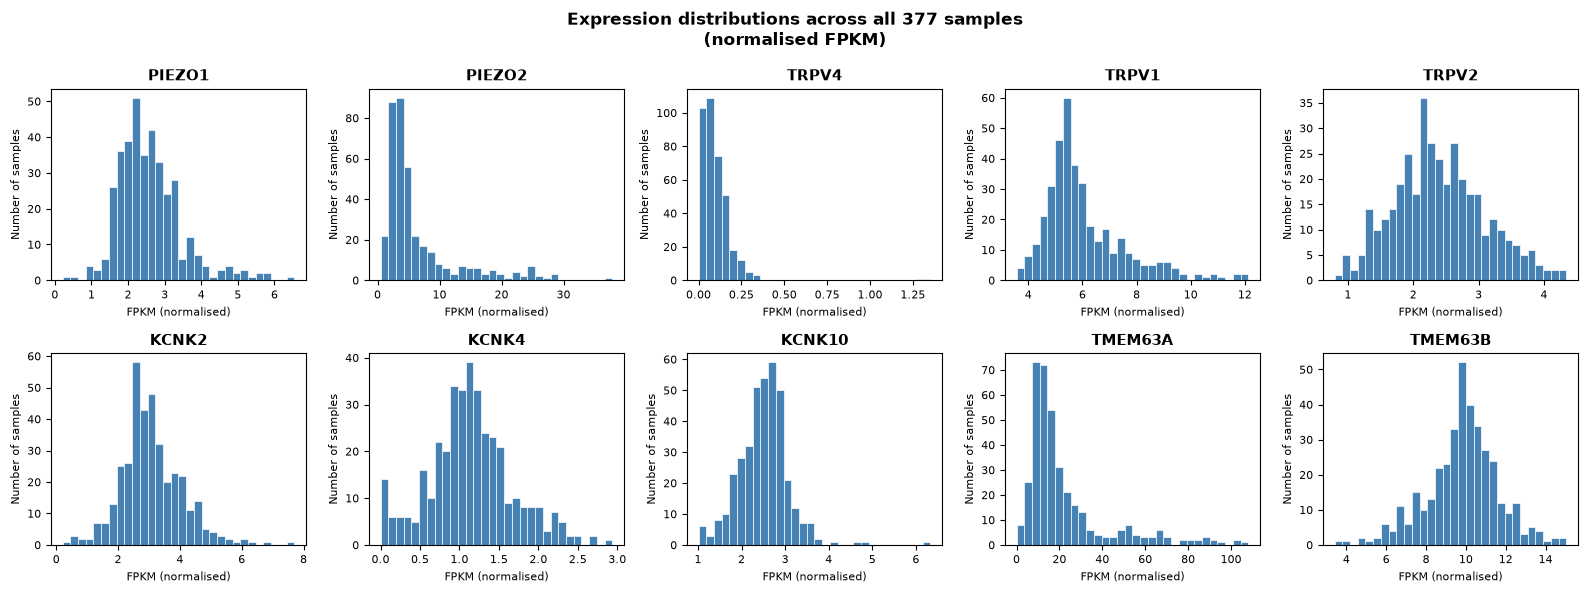

Saved figure.


In [104]:
# visual QC: plot the distribution of expression values for each target gene
# checks for outlier samples or genes with suspiciously extreme values

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
axes = axes.flatten()

gene_cols = list(target_genes_confirmed.keys())

for i, gene in enumerate(gene_cols):
    axes[i].hist(merged[gene], bins=30, color='steelblue', edgecolor='white', linewidth=0.5)
    axes[i].set_title(gene, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('FPKM (normalised)', fontsize=8)
    axes[i].set_ylabel('Number of samples', fontsize=8)
    axes[i].tick_params(labelsize=8)

plt.suptitle('Expression distributions across all 377 samples\n(normalised FPKM)', 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/01_expression_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved figure.")

## Notebook 1 Summary

- 377 samples loaded across 4 brain regions from 107 donors (54 no-TBI, 53 TBI)
- All 10 target mechanosensitive channel genes confirmed present in dataset
- Expression distributions are broadly acceptable for downstream analysis
- **TRPV4** shows very low expression (FPKM < 1.3) —> should be interpret with caution
- **TMEM63A** and **PIEZO2** show right-skewed distributions
- No samples excluded at this stage